# Lecture 23: Image Classification and Transfer Learning

This notebook is mostly a cut and paste of:

1. [Keras Image Classiciation Example](https://keras.io/examples/vision/image_classification_from_scratch/)
1. [Keras Transfer Learning Example](https://keras.io/examples/vision/keypoint_detection/)
1. [Keras Transfer Learning Documentation](https://keras.io/guides/transfer_learning/)

## Plan

The plan for today is to setup a image classification scenario where there are insufficient examples in the training set, necessitating the use of Transfer Learning.

## Image Classification Example

This section is basically a cut and paste of the [Keras Image Classiciation Example](https://keras.io/examples/vision/image_classification_from_scratch/), so I won't copy and paste the text also. We will follow the example from the Keras page.

Differences are:
* To "simulate" the cirmumstance of small training sample, we'll delete all but 100 images of each class.
* We will only train a few epochs to demonstrate it's not doing well.
* We use a slightly larger image size (for compatibility with more models for transfer learning).


In [1]:
import os
import numpy as np
import keras
from keras import layers
from tensorflow import data as tf_data
import matplotlib.pyplot as plt


## The problem, and why it is a normal one

"I want to build a classifier that separates cats from dogs, but for some reason I only have 100
pictures of cats and 100 pictures of dogs." That is not an artificial handicap. A typical real problem
looks like a lab with a hundred patients' X-rays, each labelled by a radiologist: only a hundred images.
Two problems come at once: **very little data**, and **little computing**. A network trained from scratch
fails here; a network that someone else has already trained on millions of images, with a new last layer
for our task, works. That second idea is **transfer learning**.

**An image is a tensor.** A colour image is a 3-D array: height × width × 3 **channels** (red, green and
blue), each **pixel** value from 0 to 255. A batch of images adds a first index, so it is 4-D:
(images, height, width, channels). Everything below is about getting such arrays into a network
efficiently.

We are downloading the data here. Note that it's commented out because we only need to do this once.

In [2]:
#!curl -O https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip

The download is Microsoft's copy of the Kaggle "Dogs vs. Cats" data (the Asirra project), 787 MB:
25,000 JPEG photos, 12,500 of each, released under the CDLA-Permissive-2.0 licence. `curl` and `unzip`
are Linux and macOS commands; on Windows run them inside WSL, or use Python's `zipfile` module.

We also only need to unzip once.

In [3]:
#!unzip -q kagglecatsanddogs_5340.zip
!ls

 CDLA-Permissive-2.0.pdf   kagglecatsanddogs_5340.zip
 PetImages		  'readme[1].txt'


In [4]:
!ls PetImages

Cat  Dog


**The folders are the labels.** `PetImages` has one sub-folder per class, `Cat` and `Dog`. "That's how
you're doing your ground truth: in the organizational structure of the directories." The loader below
turns folder names into labels, in alphabetical order: Cat is 0, Dog is 1.

And we only need to delete the extra images only once.

In [5]:
#  num_skipped = 0
# for folder_name in ("Cat", "Dog"):
#     max_images = 100
#     folder_path = os.path.join("PetImages", folder_name)
#     for image_i,fname in enumerate(os.listdir(folder_path)):
#         fpath = os.path.join(folder_path, fname)
#         try:
#             fobj = open(fpath, "rb")
#             is_jfif = b"JFIF" in fobj.peek(10)
#         finally:
#             fobj.close()

#         if image_i > max_images or not is_jfif:
#             num_skipped += 1
#             # Delete corrupted image
#             os.remove(fpath)

# print(f"Deleted {num_skipped} images.")

**Bad images.** Downloads like this contain broken files: here two are empty, and others are not proper
JPEGs. They matter because of when they bite: "imagine you're trained for a long time, and suddenly you
pick up an image that's not good, and that makes the whole job crash." So check before a big run. The
cell above opens each file and looks for the bytes `JFIF` near the start, the header of a common JPEG
layout, without decoding the image; files without it, and every file after the first 101 of each folder,
are **deleted**. The general strategy: skip a file that fails, put it on a list, and look at it later.

Two warnings about this cell. It is destructive: to undo it you have to unzip again. And which files
survive depends on the order the computer lists them in, so every computer keeps a different set: on the
computer that produced the outputs below it kept 96 cats and 88 dogs, not 101 of each. (To
run it, uncomment it and remove the space before `num_skipped`.)

Note the image size change:

In [6]:
#image_size = (180, 180)
image_size = (224, 224)

batch_size = 10

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    "PetImages",
    validation_split=0.2,
    subset="both",
    seed=1337,
    image_size=image_size,
    batch_size=batch_size,
)

Found 184 files belonging to 2 classes.
Using 148 files for training.
Using 36 files for validation.


`image_dataset_from_directory` builds the training and validation datasets from the folders:

- every image is **resized** to 224 × 224, because a network needs inputs of one size (and 224 is the size
  the pre-trained model below was trained at). Pictures that aren't square get squashed;
- 20% of the files are held out for **validation**, and `subset="both"` returns both halves at once;
- the **seed** fixes which files go where. A fixed seed makes the random choice repeatable: if something
  crashes, the next run hits the same files. (For an **ensemble**, several models whose answers are
  combined, you would give each a different seed.)

Reading images costs time: each file must be read and **decoded** from its compressed format, and at
training scale "that time ends up being the dominating factor." So the datasets are **generators**: they
produce batches as they are needed, and with `prefetch` (below) the CPU prepares the next batch while the
network trains on this one. Otherwise GPUs that cost thousands of dollars sit idle.

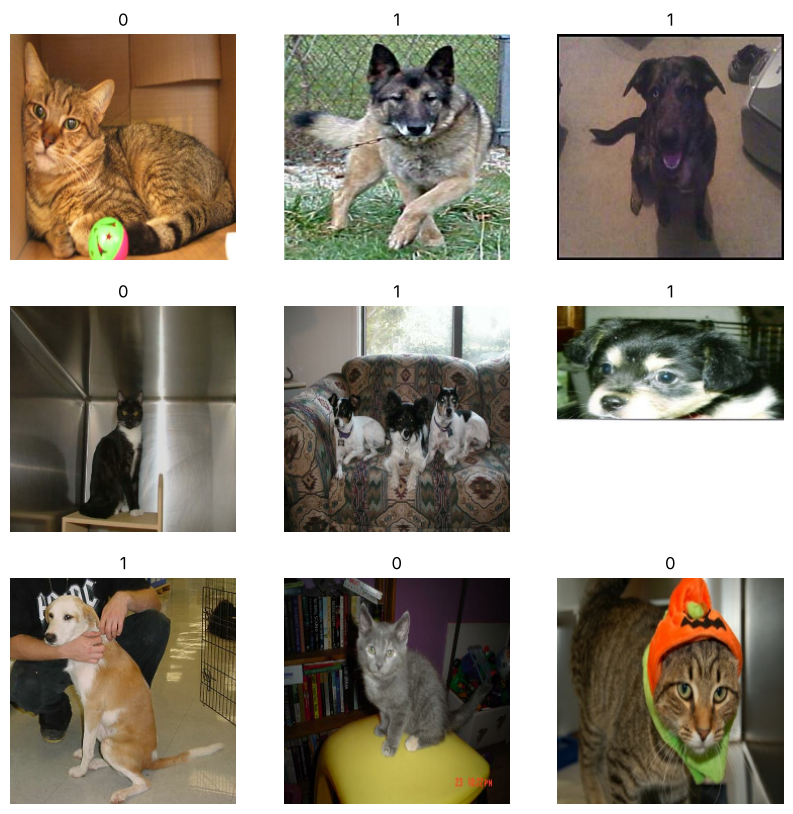

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(images[i]).astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")

**Look at your data.** "You can't make histograms of images. Here, I have to actually look at images."
`take(1)` takes one batch from the generator: a tensor of images, shape (10, 224, 224, 3), and a tensor of
labels. The titles are the labels: 0 for a cat, 1 for a dog. `imshow` wants integers for 0–255 colours,
hence `astype("uint8")`.

In [ ]:
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
]


def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images

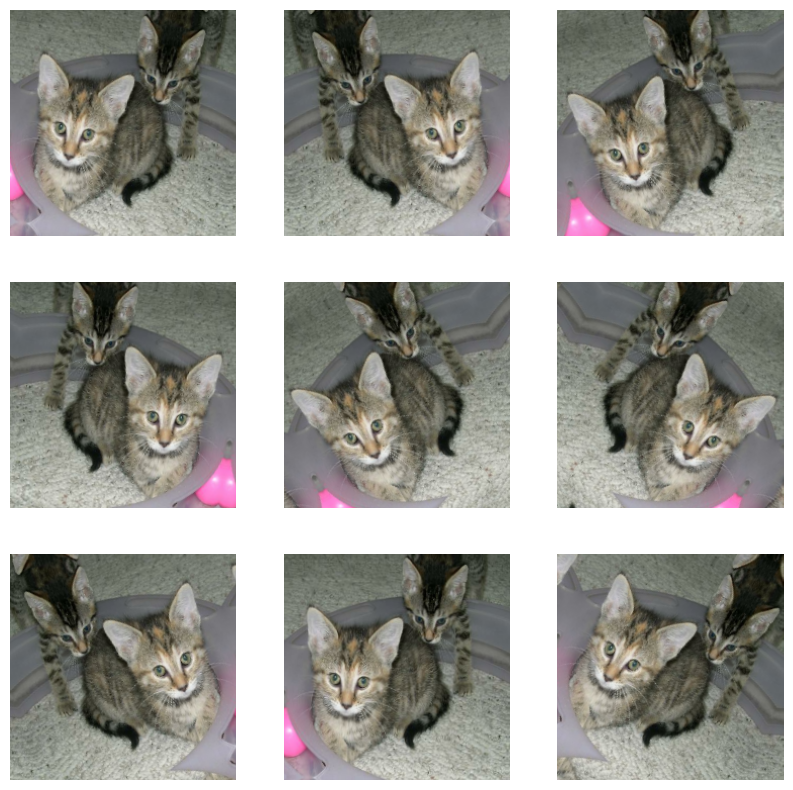

In [9]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")

## Data augmentation

"If I take this picture of this cat, and I zoomed out or zoomed in, rotate, flip, it should be identified
as a picture of a cat." **Data augmentation** applies random changes that keep the label, and it has two
purposes:

- **more training examples**: every epoch sees a slightly different version of each photo;
- **invariance**: the network learns that the answer should not change when the picture is flipped or
  turned. If every cat in the training set were in the centre, a cat in the corner might fail.

`RandomFlip("horizontal")` mirrors half the images; `RandomRotation(0.1)` turns them by up to 10% of a full
turn, ±36°. Augmentation is applied to the **training** images only: the validation images are left as
they are. The augmentation layers are just functions, so they can also go inside the model itself.

In [10]:
# Apply `data_augmentation` to the training images.
train_ds = train_ds.map(
    lambda img, label: (data_augmentation(img), label),
    num_parallel_calls=tf_data.AUTOTUNE,
)
# Prefetching samples in GPU memory helps maximize GPU utilization.
train_ds = train_ds.prefetch(tf_data.AUTOTUNE)
val_ds = val_ds.prefetch(tf_data.AUTOTUNE)

In [11]:
def make_model(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    # Entry block
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x  # Set aside residual

    for size in [256, 512, 728]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # Project residual
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(
            previous_block_activation
        )
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    if num_classes == 2:
        units = 1
    else:
        units = num_classes

    x = layers.Dropout(0.25)(x)
    # We specify activation=None so as to return logits
    outputs = layers.Dense(units, activation=None)(x)
    return keras.Model(inputs, outputs)


model = make_model(input_shape=image_size + (3,), num_classes=2)
#keras.utils.plot_model(model, show_shapes=True)

## A small convolutional network, layer by layer

This is a small version of the networks used for images (keras.io calls it a small Xception; its skip
connections come from ResNet). "The details don't matter," but the names will come up again:

- `Rescaling(1.0 / 255)`: pixel values from 0–255 to 0–1, as a layer.
- `Conv2D(128, 3, strides=2, padding="same")`: 128 **filters** of 3 × 3 pixels, moved 2 pixels at a time
  (the **stride**), with the edges padded so the output keeps its shape. Each filter is a small detector
  (see the slides on convolutional networks).
- `BatchNormalization()`: rescales a layer's outputs to mean 0 and spread 1 over the batch, which helps
  the descent. It keeps running averages of those statistics, stored as non-trainable weights, to use
  when predicting.
- `SeparableConv2D`: a cheaper convolution: one 3 × 3 filter per channel, then a 1 × 1 convolution that
  mixes the channels.
- `MaxPooling2D(3, strides=2)`: keeps the largest value in each small block, halving the size: 224 → 112 →
  56 → 28 → 14 pixels across the network.
- The **residual** (skip) connection adds a block's input to its output (a 1 × 1 convolution reshapes it to
  match), so the block only has to learn a correction.
- `GlobalAveragePooling2D()`: averages each feature map to one number.
- The last layer has one output and no activation: a **logit**, the value before the sigmoid.

In [12]:
epochs = 8

callbacks = [
    keras.callbacks.ModelCheckpoint("save_at_{epoch}.keras"),
]
model.compile(
    optimizer=keras.optimizers.Adam(3e-4),  # Fixed 2026-10: Keras 3 has no legacy optimizers (was legacy.Adam)
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="acc")],
)

history = model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds,
)

Epoch 1/8


/tmp/claude-0/-home-user/e801ee84-a749-5f5d-a4a6-6eb632fd36f9/scratchpad/kvenv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


15/15 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - acc: 0.5811 - loss: 0.7630 - val_acc: 0.5278 - val_loss: 0.6926
Epoch 2/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - acc: 0.5608 - loss: 0.6850 - val_acc: 0.5278 - val_loss: 0.6921
Epoch 3/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - acc: 0.5608 - loss: 0.6514 - val_acc: 0.5278 - val_loss: 0.6918
Epoch 4/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - acc: 0.6351 - loss: 0.6176 - val_acc: 0.5278 - val_loss: 0.6917
Epoch 5/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - acc: 0.6554 - loss: 0.6382 - val_acc: 0.5278 - val_loss: 0.6922
Epoch 6/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - acc: 0.6351 - loss: 0.6157 - val_acc: 0.5278 - val_loss: 0.6933
Epoch 7/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - acc: 0.6351 - loss: 0.6679 - val_acc: 0.5278 - val_loss: 0.6940
Epoch 8/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - acc: 0.6892 - loss: 0.5667 - val_acc: 0.5278 - val_loss: 0.6951


`BinaryCrossentropy(from_logits=True)` tells the loss that the model outputs logits, so the loss applies
the sigmoid itself: a log and an exponential cancel, which is numerically more stable. The metric is
**binary accuracy**, the fraction of images on the right side of 0.5 after the sigmoid. Each epoch is
15 steps of 10 images (148 training images); the checkpoint callback saves the model after each
epoch (callbacks were explained in the Keras lecture).

**Corrected 2026-10:** the optimizer was `keras.optimizers.legacy.Adam`, which Keras 3 removed; it is now
`keras.optimizers.Adam`, with the same learning rate.

As you can see, the model doesn't perform very well on this small dataset. It also takes a very long time to go through the data on this laptop without a GPU.

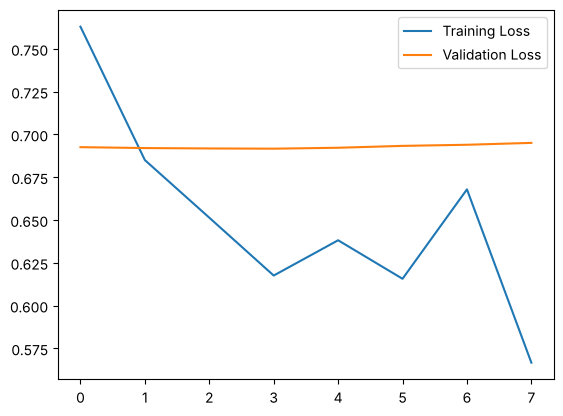

In [13]:
plt.plot(range(len(history.history["loss"])),history.history["loss"],label="Training Loss")
plt.plot(range(len(history.history["val_loss"])),history.history["val_loss"],label="Validation Loss")
plt.legend()

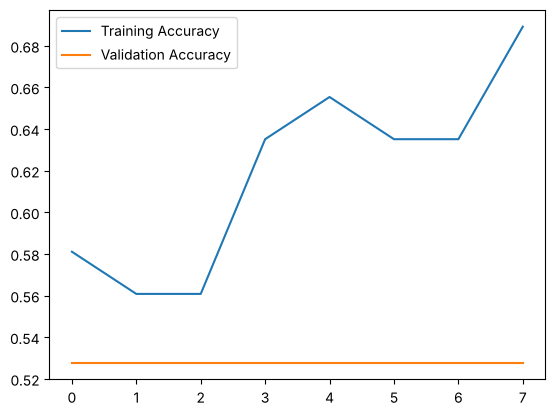

In [14]:
plt.plot(range(len(history.history["acc"])),history.history["acc"],label="Training Accuracy")  # Fixed 2026-10: the labels said Loss
plt.plot(range(len(history.history["val_acc"])),history.history["val_acc"],label="Validation Accuracy")
plt.legend()

**Reading the result.** Training accuracy creeps up, from 0.58 to 0.69, but validation accuracy is 0.528 at every epoch: 19 of the 36 validation images, which is exactly what you get by giving every image the same answer. The validation loss stays at about 0.69, which is ln 2, the loss of answering 50/50 for everything. Nothing the network learns carries over to new pictures. (A model that merely learned badly would wobble from epoch to epoch; one this flat answers the same thing for every image. The run in class showed the same pattern. Part of the reason may be batch normalization: at validation it uses running averages that have had only 120 updates to move from their starting values.) "If I was doing this with millions of images, it would be happy":
a network that has to learn what edges, fur and eyes look like from 148 photos has far too little to
go on.

(**Corrected 2026-10:** these accuracy plots were labelled "Loss".)

## Transfer Learning

Now we will follow [Keras Transfer Learning Example](https://keras.io/examples/vision/keypoint_detection/), which is setup for a different task (object detection).

Differences from that example:
* Using the same cat/dog dataset as before.
* Changing task from object detection to classification, using exactly the same final layers as the model above.
* Wrapping things in functions that mirror what we did above.

In [16]:
def make_transfer_model(input_shape, num_classes):
    # Load the pre-trained weights of MobileNetV2 and freeze the weights
    backbone = keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape,
    )
    backbone.trainable = False

    inputs = layers.Input(input_shape)
    x = keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = backbone(x)
    x = layers.Dropout(0.3)(x)
    
    x = layers.GlobalAveragePooling2D()(x)
    if num_classes == 2:
        units = 1
    else:
        units = num_classes

    x = layers.Dropout(0.25)(x)
    # We specify activation=None so as to return logits
    outputs = layers.Dense(units, activation=None)(x)

    return keras.Model(inputs, outputs, name="keypoint_detector")

In [17]:
model2 = make_transfer_model(input_shape=image_size + (3,), num_classes=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## The transfer model

"Keras has built in a large library of standard models that have been pre-trained." **MobileNetV2** is a
small convolutional network designed to run on phones, trained on **ImageNet**: 1.2 million photos in 1,000
classes. Here it is the **backbone**, the part that turns an image into features:

- `weights="imagenet"` downloads the trained weights (about 9 MB, once).
- `include_top=False` drops its last layers, which have "1,000 outputs for 1,000 different classes. I
  don't want that; I'm going to put a new top on there just for my task." ("They call it top. I would call
  it the bottom": it is the output end.)
- `backbone.trainable = False` **freezes** it: training will not change its 2.26 million weights. It could
  be trained, but it is very large and doesn't need to be.
- `preprocess_input` scales the pixels to the range MobileNetV2 was trained with, −1 to 1.

What is trained is the new head: a `Dense(1)` on 1,280 pooled features, **1,281 weights**. The rest of
the model is the same as before: "The only real difference is I'm using a pre-built one." (The name
`keypoint_detector` is left over from the keras.io example this code was cut from.)

In [18]:
epochs = 8

callbacks = [
    keras.callbacks.ModelCheckpoint("save_at_{epoch}.keras"),
]
model2.compile(
    optimizer=keras.optimizers.Adam(3e-4),  # Fixed 2026-10: Keras 3 has no legacy optimizers (was legacy.Adam)
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="acc")],
)

history = model2.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds,
)

Epoch 1/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 244ms/step - acc: 0.5000 - loss: 0.8277 - val_acc: 0.5000 - val_loss: 0.7430
Epoch 2/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 178ms/step - acc: 0.5676 - loss: 0.6613 - val_acc: 0.5556 - val_loss: 0.6038
Epoch 3/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 168ms/step - acc: 0.7095 - loss: 0.5214 - val_acc: 0.6944 - val_loss: 0.4882
Epoch 4/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - acc: 0.7905 - loss: 0.4334 - val_acc: 0.7500 - val_loss: 0.4117
Epoch 5/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - acc: 0.8378 - loss: 0.3346 - val_acc: 0.8611 - val_loss: 0.3501
Epoch 6/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - acc: 0.8446 - loss: 0.3373 - val_acc: 0.8611 - val_loss: 0.3036
Epoch 7/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - acc: 0.8514 - loss: 0.3241 - val_acc: 0.8611 - val_loss: 0.2753
Epoch 8/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - acc: 0.8919 - loss: 0.2603 - val_acc: 0.9167 - val_loss: 0.2372


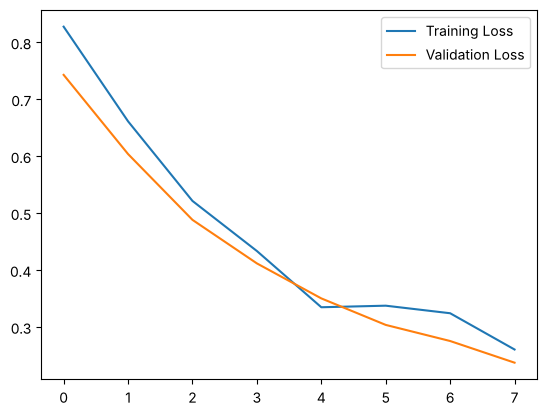

In [19]:
plt.plot(range(len(history.history["loss"])),history.history["loss"],label="Training Loss")
plt.plot(range(len(history.history["val_loss"])),history.history["val_loss"],label="Validation Loss")
plt.legend()

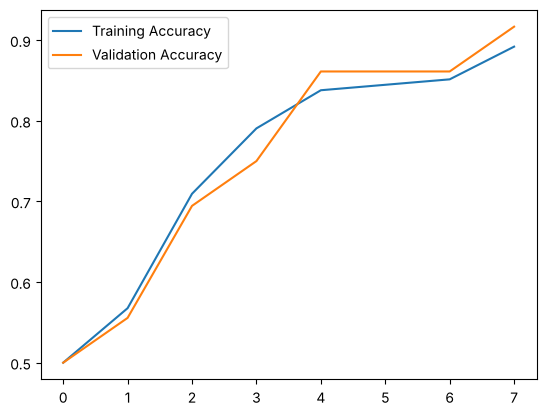

In [20]:
plt.plot(range(len(history.history["acc"])),history.history["acc"],label="Training Accuracy")  # Fixed 2026-10: the labels said Loss
plt.plot(range(len(history.history["val_acc"])),history.history["val_acc"],label="Validation Accuracy")
plt.legend()

## Why it works, and what next

Validation accuracy climbs from 0.50 to 0.92 by epoch 8 (33 of the 36 validation images), and each epoch takes about 3 seconds, against about 20 for the network trained from scratch: only 1,281 weights are being trained. (The run in class reached 0.975.) "This model has already learned how to deal with images": edges, textures, changes in
shading. "All I'm really learning is that one layer."

**Fine-tuning.** You could also let the backbone train ("fine-tune the features so that they'll be better
for recognizing cats and dogs"), which is worth it when your images are not much like ImageNet's, and costs
much more computing. Keras' recipe: build the model with `backbone(x, training=False)`, so its batch
normalization stays in prediction mode; after training the head, set `backbone.trainable = True`,
**compile again**, and train with a very small learning rate, such as `keras.optimizers.Adam(1e-5)`. Setting
`trainable = True` alone would let the first big steps wreck what the backbone learned.

**The moral.** When you don't have much data, or much computing: transfer learning. It works for images,
audio, and now language models. Medical images still benefit from features learned on everyday photos.
And to get started: "in Keras, whatever you want to do, you will find an example that will get you quite a
ways there." Start from such an example, which you can run and understand, rather than from code an LLM
wrote.

**Try it:** use another image dataset, or test whether the augmentation actually helps here, by training
with and without it.

**Note:** both runs above save their checkpoints as `save_at_1.keras` … `save_at_8.keras`, so the second run
overwrites the first model's files.